# 02 小兔鲜儿 - 首页模块


本篇承接 01 的项目准备，按配套讲义 `rabbit-shop/02-首页模块.md` 的顺序完成首页：自定义导航栏 → 通用轮播组件 → 首页分类 → 热门推荐 → 猜你喜欢 → 下拉刷新 → 骨架屏。

主要知识点是组件自动导入、父子组件通信、接口类型与数据渲染、触底分页和下拉刷新。公共请求函数继续使用 01 封装的 `http<T>`。

资料来自[课程网盘](https://pan.baidu.com/s/1uhQQvqs9ESRvhEvgzgSUWQ?pwd=9988)，提取码 `9988`，配套包为 `02-笔记.rar`。本篇的 8 张教学图片直接内嵌在 Notebook 中。

| 文件 | 本篇职责 |
| --- | --- |
| `src/pages/index/index.vue` | 首页数据、滚动触底、刷新与加载状态 |
| `src/pages/index/components/CustomNavbar.vue` | 首页自定义导航与安全区适配 |
| `src/components/XtxSwiper.vue` | 首页与分类页复用的轮播 |
| `src/pages/index/components/CategoryPanel.vue` | 首页分类入口 |
| `src/pages/index/components/HotPanel.vue` | 首页热门推荐 |
| `src/components/XtxGuess.vue` | 多页面复用的猜你喜欢和分页状态 |
| `src/services/home.ts` | 首页接口函数 |
| `src/types/home.d.ts`、`src/types/global.d.ts` | 业务类型、通用分页类型 |
| `src/types/components.d.ts` | 全局组件与组件实例类型 |
| `src/pages.json` | 页面导航和 easycom 规则 |

原稿少量代码为局部片段。本篇保留静态结构和动态改造的过程；需要修正的拼写、导入和刷新逻辑会在对应位置说明。


## 自定义导航栏

默认导航栏不能直接表达首页的 Logo、标语和搜索条，因此把它替换为自己的组件。机型的状态栏、刘海和顶部安全区不同，布局还需要适配这些差异。

操作顺序：准备组件静态结构 → 隐藏页面默认导航栏 → 使用安全区数据设置顶部占位。

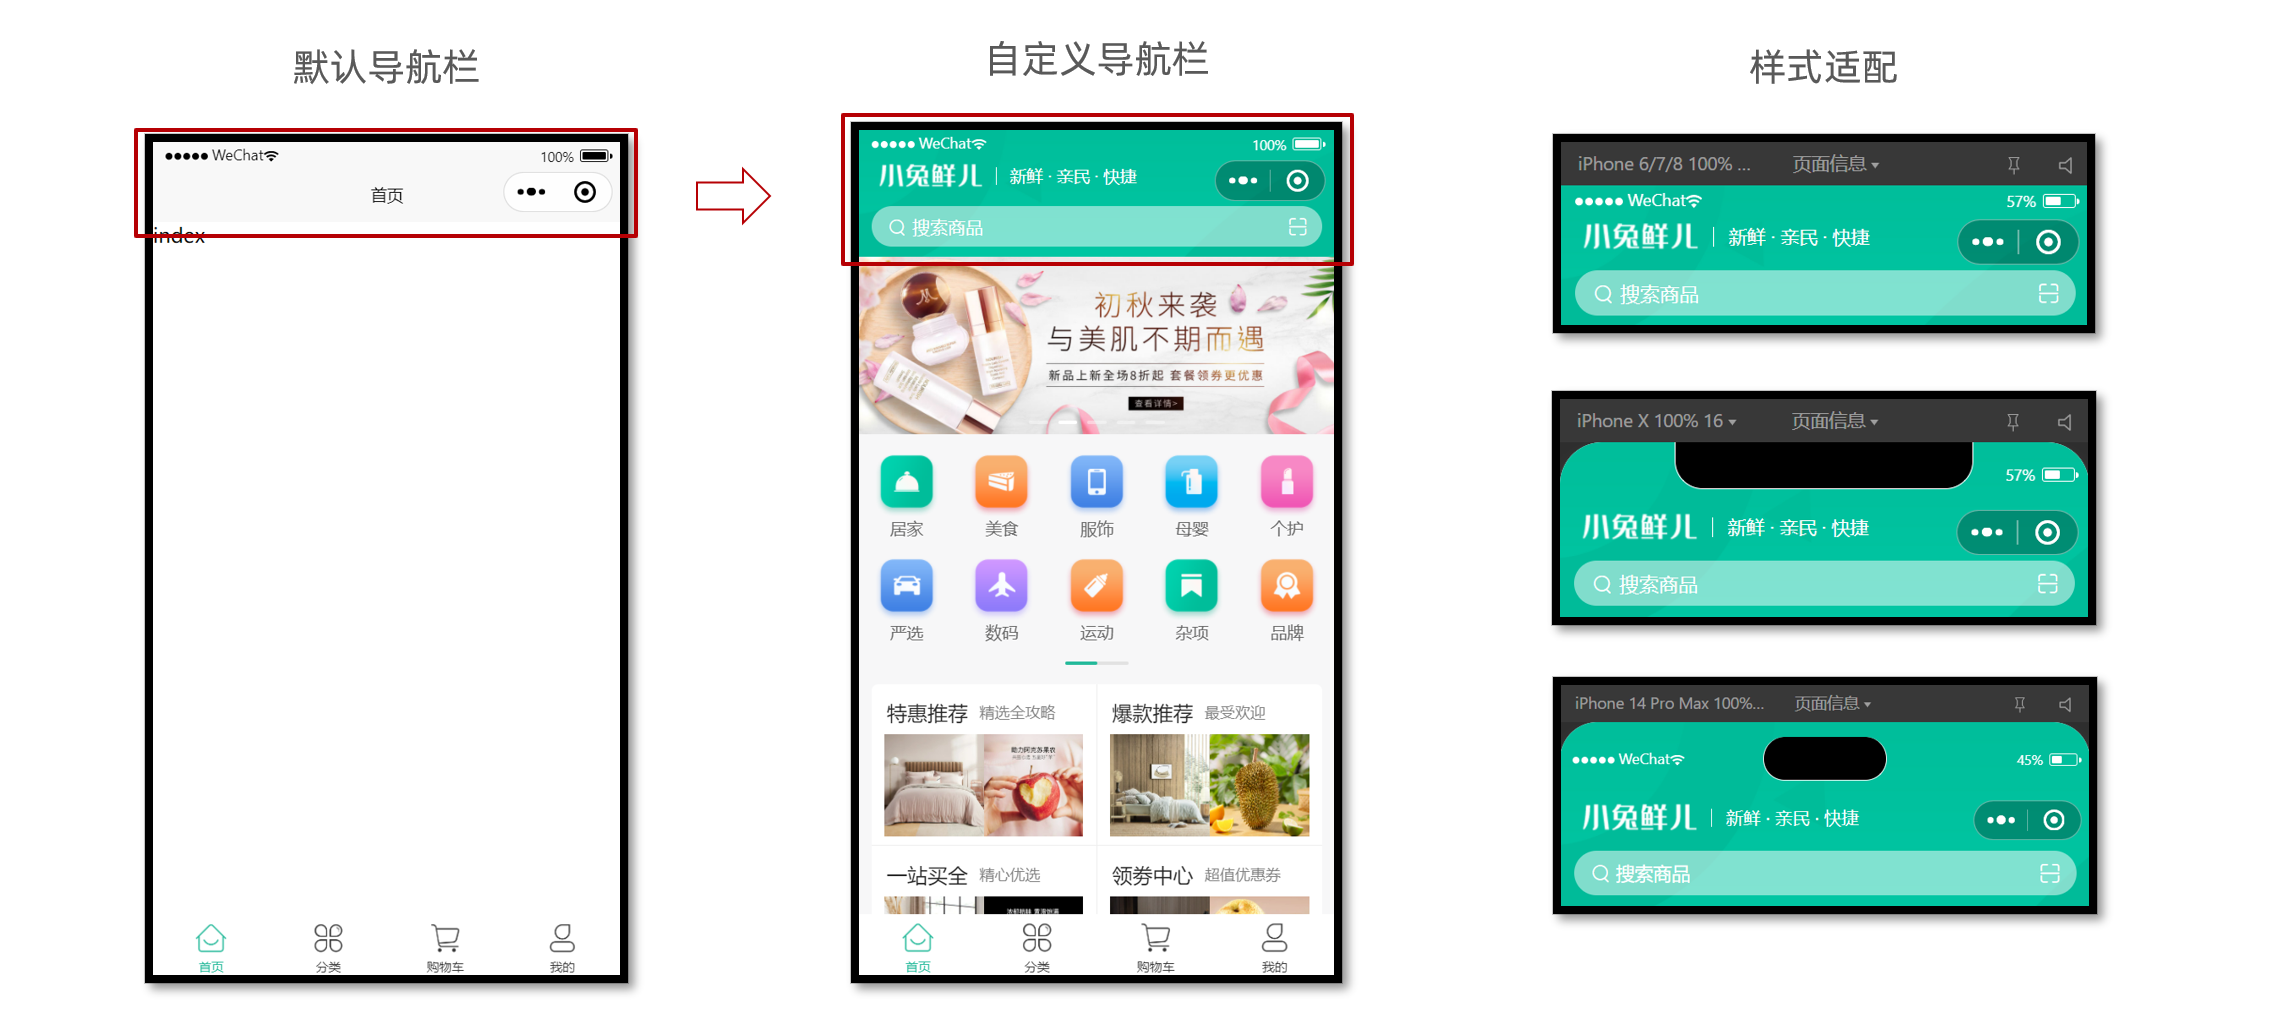


### 准备导航栏组件

新建 `src/pages/index/components/CustomNavbar.vue`，使用模板已有的 Logo、导航背景和图标字体素材。

> **原稿拼写修正**：讲义前面的路径写成了 `componets`，本篇统一使用 `components`，与首页其他业务组件目录一致。

先实现静态结构：


```vue
<script setup lang="ts">
//
</script>

<template>
  <view class="navbar">
    <!-- logo文字 -->
    <view class="logo">
      <image class="logo-image" src="@/static/images/logo.png"></image>
      <text class="logo-text">新鲜 · 亲民 · 快捷</text>
    </view>
    <!-- 搜索条 -->
    <view class="search">
      <text class="icon-search">搜索商品</text>
      <text class="icon-scan"></text>
    </view>
  </view>
</template>

<style lang="scss">
/* 自定义导航条 */
.navbar {
  background-image: url(@/static/images/navigator_bg.png);
  background-size: cover;
  position: relative;
  display: flex;
  flex-direction: column;
  padding-top: 20px;
  .logo {
    display: flex;
    align-items: center;
    height: 64rpx;
    padding-left: 30rpx;
    padding-top: 20rpx;
    .logo-image {
      width: 166rpx;
      height: 39rpx;
    }
    .logo-text {
      flex: 1;
      line-height: 28rpx;
      color: #fff;
      margin: 2rpx 0 0 20rpx;
      padding-left: 20rpx;
      border-left: 1rpx solid #fff;
      font-size: 26rpx;
    }
  }
  .search {
    display: flex;
    align-items: center;
    justify-content: space-between;
    padding: 0 10rpx 0 26rpx;
    height: 64rpx;
    margin: 16rpx 20rpx;
    color: #fff;
    font-size: 28rpx;
    border-radius: 32rpx;
    background-color: rgba(255, 255, 255, 0.5);
  }
  .icon-search {
    &::before {
      margin-right: 10rpx;
    }
  }
  .icon-scan {
    font-size: 30rpx;
    padding: 15rpx;
  }
}
</style>
```

`logo` 区域显示品牌和标语，`search` 区域显示搜索与扫码图标。当前主要完成外观，点击行为没有在本节实现。静态样式里的 `padding-top: 20px` 只是初始占位，下一步用机型数据替换。


### 隐藏默认导航栏并适配安全区域

在 `src/pages.json` 的 `pages` 数组中，修改已有的首页配置项，保留其他页面：


```jsonc
// src/pages.json
{
  "path": "pages/index/index",
  "style": {
    "navigationStyle": "custom", // 隐藏默认导航
    "navigationBarTextStyle": "white",
    "navigationBarTitleText": "首页"
  }
}
```

`navigationStyle: "custom"` 隐藏默认导航栏，`navigationBarTextStyle: "white"` 设置导航文字风格。自定义导航的颜色、Logo 和搜索条由组件自己绘制。

安全区用于避免重要内容被状态栏、刘海或底部系统操作区域遮挡。原课通过 `uni.getSystemInfoSync()` 读取 `safeAreaInsets`，单位是 **px**，不是 `rpx`。

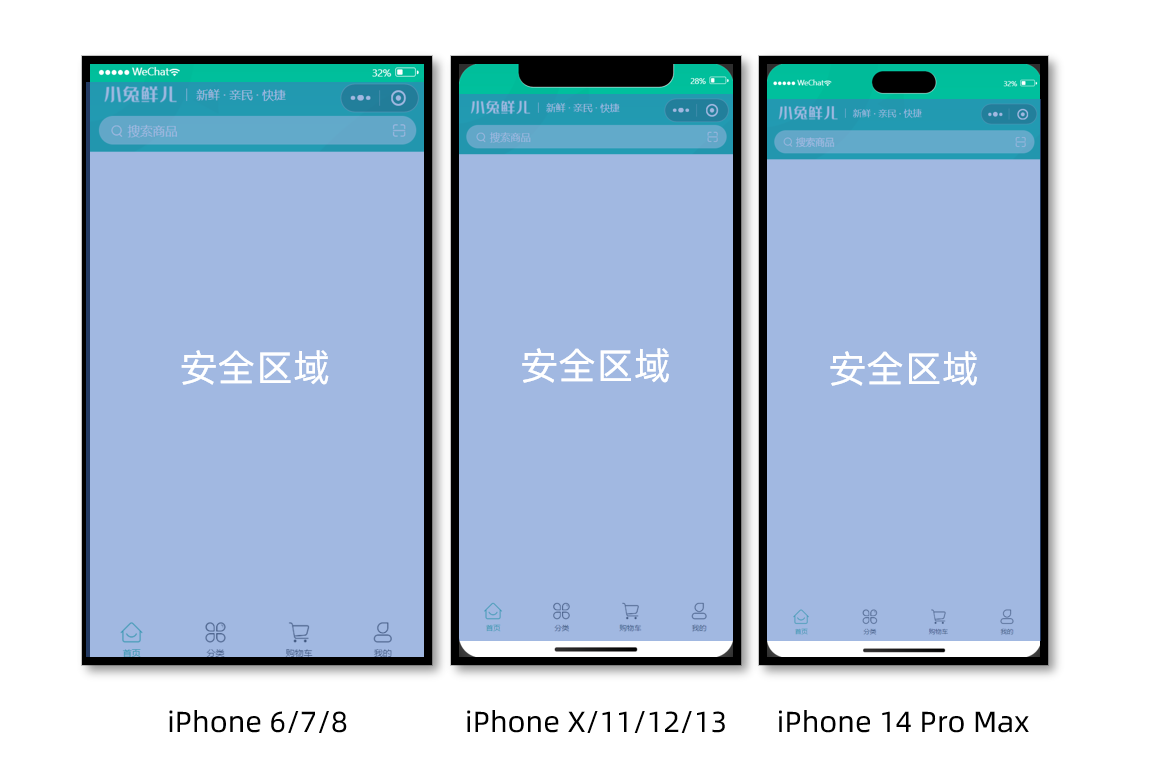


在 `CustomNavbar.vue` 中把顶部 padding 改为安全区距离，其他模板结构和 SCSS 保留：

> **片段修正**：原稿使用普通 `<script>`，不能直接把顶层变量暴露给模板；这里与完整组件一致，使用 `<script setup lang="ts">`。同时在安全区值缺失时回退为 0，避免得到 `undefinedpx`。


```vue
<!-- src/pages/index/components/CustomNavbar.vue -->
<script setup lang="ts">
// 获取屏幕边界到安全区域距离
const { safeAreaInsets } = uni.getSystemInfoSync()
</script>

<template>
  <!-- 顶部占位 -->
  <view class="navbar" :style="{ paddingTop: (safeAreaInsets?.top ?? 0) + 'px' }">
    <!-- ...省略 -->
  </view>
</template>
```

完成后分别切换普通屏幕和刘海屏模拟机型，确认顶部内容不会进入系统状态栏区域。原课使用的系统信息 API 按模板版本跟做。


## 通用轮播组件

首页和商品分类页都有广告位，所以轮播组件放在 `src/components`，作为公共组件 `XtxSwiper`。父页面负责取得广告数据，组件接收 `list` 并渲染。

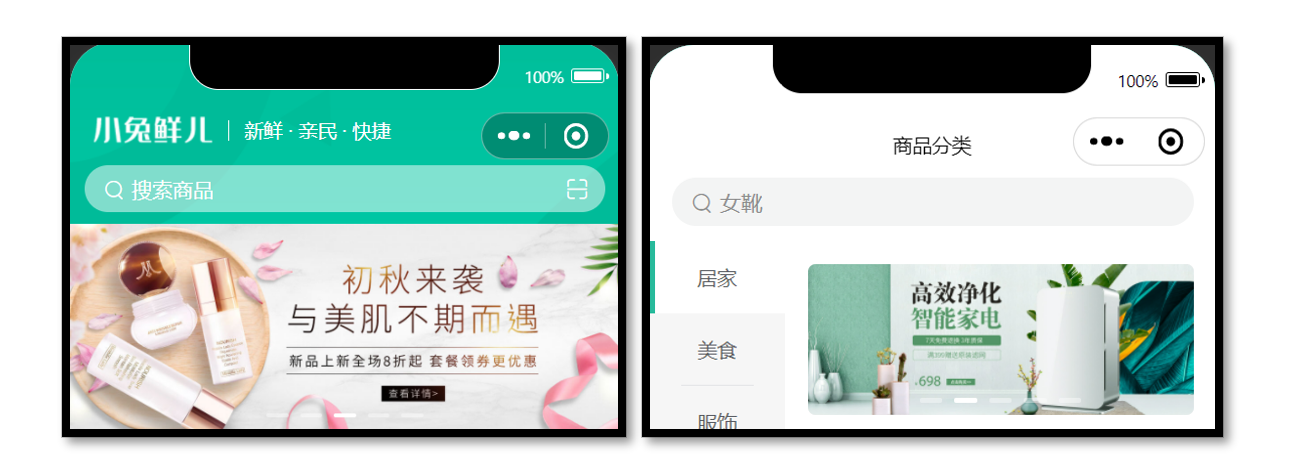


### 准备轮播的静态结构

新建 `src/components/XtxSwiper.vue`，先用三个固定广告测试布局：


```vue
<script setup lang="ts">
import { ref } from 'vue'

const activeIndex = ref(0)
</script>

<template>
  <view class="carousel">
    <swiper :circular="true" :autoplay="false" :interval="3000">
      <swiper-item>
        <navigator url="/pages/index/index" hover-class="none" class="navigator">
          <image
            mode="aspectFill"
            class="image"
            src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/slider_1.jpg"
          ></image>
        </navigator>
      </swiper-item>
      <swiper-item>
        <navigator url="/pages/index/index" hover-class="none" class="navigator">
          <image
            mode="aspectFill"
            class="image"
            src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/slider_2.jpg"
          ></image>
        </navigator>
      </swiper-item>
      <swiper-item>
        <navigator url="/pages/index/index" hover-class="none" class="navigator">
          <image
            mode="aspectFill"
            class="image"
            src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/slider_3.jpg"
          ></image>
        </navigator>
      </swiper-item>
    </swiper>
    <!-- 指示点 -->
    <view class="indicator">
      <text
        v-for="(item, index) in 3"
        :key="item"
        class="dot"
        :class="{ active: index === activeIndex }"
      ></text>
    </view>
  </view>
</template>

<style lang="scss">
:host {
  display: block;
  height: 280rpx;
}
/* 轮播图 */
.carousel {
  height: 100%;
  position: relative;
  overflow: hidden;
  transform: translateY(0);
  background-color: #efefef;
  .indicator {
    position: absolute;
    left: 0;
    right: 0;
    bottom: 16rpx;
    display: flex;
    justify-content: center;
    .dot {
      width: 30rpx;
      height: 6rpx;
      margin: 0 8rpx;
      border-radius: 6rpx;
      background-color: rgba(255, 255, 255, 0.4);
    }
    .active {
      background-color: #fff;
    }
  }
  .navigator,
  .image {
    width: 100%;
    height: 100%;
  }
}
</style>
```

`swiper` 是内置滑动容器，`swiper-item` 是每一项。`circular` 开启循环，`interval` 设置自动切换间隔；本例 `autoplay` 为 `false`，所以不会自动播放。

原课另外绘制指示点，通过 `activeIndex` 标记当前项。静态阶段还没有处理滑动事件，下一步接入数据时再同步下标。后续替换脚本、模板时，保留这里的完整 SCSS。


### 自动导入与全局组件类型

在 `src/pages.json` 的 `easycom.custom` 中追加 `Xtx` 匹配规则，保留 01 的 uni-ui 规则：


```jsonc
{
  // 组件自动引入规则
  "easycom": {
    // 是否开启自动扫描 @/components/$1/$1.vue 组件
    "autoscan": true,
    // 以正则方式自定义组件匹配规则
    "custom": {
      // uni-ui 规则如下配置
      "^uni-(.*)": "@dcloudio/uni-ui/lib/uni-$1/uni-$1.vue",
      // 以 Xtx 开头的组件，在 components 目录中查找
      "^Xtx(.*)": "@/components/Xtx$1.vue"
    }
  }
}
```

`^Xtx(.*)` 会把 `XtxSwiper` 映射到 `@/components/XtxSwiper.vue`，之后的 `XtxGuess` 也会匹配同一规则。

再新建 `src/types/components.d.ts`，让编辑器认识全局组件：

> **原稿修正**：原 import 的相对路径和末尾弯引号有误；这里使用实际组件路径和标准引号，并把不可见的特殊空格整理为普通空格。


```typescript
// src/types/components.d.ts
import XtxSwiper from '@/components/XtxSwiper.vue'
declare module 'vue' {
  export interface GlobalComponents {
    XtxSwiper: typeof XtxSwiper
  }
}
```

easycom 解决运行时组件查找，`GlobalComponents` 解决开发时的组件提示与类型检查，两者都需要。

> **原课版本提示**：[Vue Language Tools](https://github.com/vuejs/language-tools) 的新版声明方式为 `declare module 'vue'`；原先针对 `@vue/runtime-core` 的写法要按版本调整。


### 获取轮播数据

首页广告接口：

| 项目 | 内容 |
| --- | --- |
| 方法 | `GET` |
| 路径 | `/home/banner` |
| Query | `distributionSite`，可选，默认 `1` |
| 投放位置 | `1` 首页，`2` 商品分类页 |

先在 `src/types/home.d.ts` 定义广告项：


```typescript
/** 首页-广告区域数据类型 */
export type BannerItem = {
  /** 跳转链接 */
  hrefUrl: string
  /** id */
  id: string
  /** 图片链接 */
  imgUrl: string
  /** 跳转类型 */
  type: number
}
```

在 `src/services/home.ts` 封装接口。原稿省略了公共请求函数导入，这里补齐：


```typescript
// 存放路径: src/services/home.ts
import { http } from '@/utils/http'
import type { BannerItem } from '@/types/home'

/**
 * 首页-广告区域-小程序
 * @param distributionSite 广告区域展示位置（投放位置 投放位置，1为首页，2为分类商品页） 默认是1
 */
export const getHomeBannerAPI = (distributionSite = 1) => {
  return http<BannerItem[]>({
    method: 'GET',
    url: '/home/banner',
    data: {
      distributionSite,
    },
  })
}
```

`distributionSite = 1` 是函数默认参数，首页直接调用即可；分类页传入 `2`。GET 请求的 `data` 会作为查询参数发送。

返回值沿用 01 的 `Data<T>` 外层结构，广告数组在 `res.result` 中，不能把整个 `res` 当作数组。


### 接收数据并同步指示点

将 `XtxSwiper.vue` 的脚本与模板替换为下面的动态版本，保留静态阶段的样式：


```vue
<script setup lang="ts">
import type { BannerItem } from '@/types/home'
import { ref } from 'vue'

const activeIndex = ref(0)

// 当 swiper 下标发生变化时触发
const onChange: UniHelper.SwiperOnChange = (ev) => {
  // ! 非空断言，主观上排除掉空值情况
  activeIndex.value = ev.detail.current
}
// 定义 props 接收
defineProps<{
  list: BannerItem[]
}>()
</script>

<template>
  <view class="carousel">
    <swiper :circular="true" :autoplay="false" :interval="3000" @change="onChange">
      <swiper-item v-for="item in list" :key="item.id">
        <navigator url="/pages/index/index" hover-class="none" class="navigator">
          <image mode="aspectFill" class="image" :src="item.imgUrl"></image>
        </navigator>
      </swiper-item>
    </swiper>
    <!-- 指示点 -->
    <view class="indicator">
      <text
        v-for="(item, index) in list"
        :key="item.id"
        class="dot"
        :class="{ active: index === activeIndex }"
      ></text>
    </view>
  </view>
</template>
```

`defineProps` 声明接收 `BannerItem[]`。广告项和指示点都遍历同一个 `list`，通过 `item.id` 作为稳定的 key。

`@change` 触发时，`ev.detail.current` 给出当前轮播下标，写入 `activeIndex` 后，指示点的 `active` 样式随之变化。父页面取得数据后使用 `<XtxSwiper :list="bannerList" />` 传入。

原稿虽然定义了 `hrefUrl` 和跳转类型，当前动态模板的导航仍然是首页占位地址；本节完成广告展示与指示点，广告跳转策略尚未接入。


## 首页分类

首页分类只在首页使用，属于页面业务组件 `CategoryPanel`，放在 `src/pages/index/components`。父页面导入并使用它，并把首页底色设置为 `#F7F7F7`。

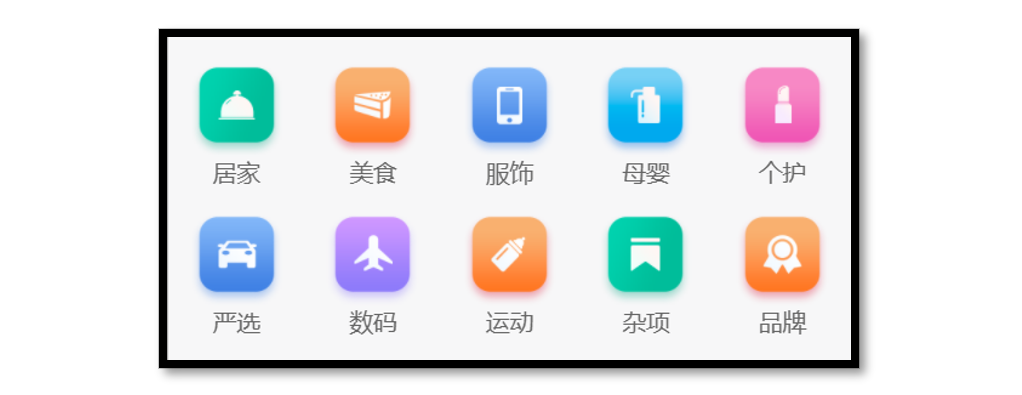


### 分类静态结构

新建 `src/pages/index/components/CategoryPanel.vue`：


```vue
<script setup lang="ts">
//
</script>

<template>
  <view class="category">
    <navigator
      class="category-item"
      hover-class="none"
      url="/pages/index/index"
      v-for="item in 10"
      :key="item"
    >
      <image
        class="icon"
        src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/images/nav_icon_1.png"
      ></image>
      <text class="text">居家</text>
    </navigator>
  </view>
</template>

<style lang="scss">
/* 前台类目 */
.category {
  margin: 20rpx 0 0;
  padding: 10rpx 0;
  display: flex;
  flex-wrap: wrap;
  min-height: 328rpx;

  .category-item {
    width: 150rpx;
    display: flex;
    justify-content: center;
    flex-direction: column;
    align-items: center;
    box-sizing: border-box;

    .icon {
      width: 100rpx;
      height: 100rpx;
    }
    .text {
      font-size: 26rpx;
      color: #666;
    }
  }
}
</style>
```

静态版本重复展示 10 项，用于确认两行分类入口的布局。容器通过 flex 换行，每个入口宽 `150rpx`。动态改造后继续保留这段 SCSS。


### 获取分类数据

分类接口为 `GET /home/category/mutli`，无需参数。接口路径中的 `mutli` 就是原课约定的拼写。

在 `src/types/home.d.ts` 中追加：


```typescript
/** 首页-前台类目数据类型 */
export type CategoryItem = {
  /** 图标路径 */
  icon: string
  /** id */
  id: string
  /** 分类名称 */
  name: string
}
```

在 `src/services/home.ts` 中追加分类接口，并把 `CategoryItem` 合并到文件顶部已有的类型导入中：


```typescript
import type { BannerItem, CategoryItem } from '@/types/home'
```

```typescript
// services/home.ts
/**
 * 首页-前台分类-小程序
 */
export const getHomeCategoryAPI = () => {
  return http<CategoryItem[]>({
    method: 'GET',
    url: '/home/category/mutli',
  })
}
```

这里的导入示例表示**替换原类型导入**，不是重复声明同名 import。公共 `http` 导入沿用轮播接口的配置。


### 渲染分类列表

将 `CategoryPanel.vue` 的脚本与模板换为：


```vue
<script setup lang="ts">
import type { CategoryItem } from '@/types/home'

// 定义 props 接收数据
defineProps<{
  list: CategoryItem[]
}>()
</script>

<template>
  <view class="category">
    <navigator
      class="category-item"
      hover-class="none"
      url="/pages/index/index"
      v-for="item in list"
      :key="item.id"
    >
      <image class="icon" :src="item.icon"></image>
      <text class="text">{{ item.name }}</text>
    </navigator>
  </view>
</template>
```

父页面传入 `<CategoryPanel :list="categoryList" />`。图标、名称和 key 分别来自 `icon`、`name`、`id`。原课此处的导航仍为首页占位地址，当前步骤只实现分类入口展示。


## 热门推荐

后端组织推荐内容，前端展示标题、说明和图片。首页业务组件 `HotPanel` 放在 `src/pages/index/components`。

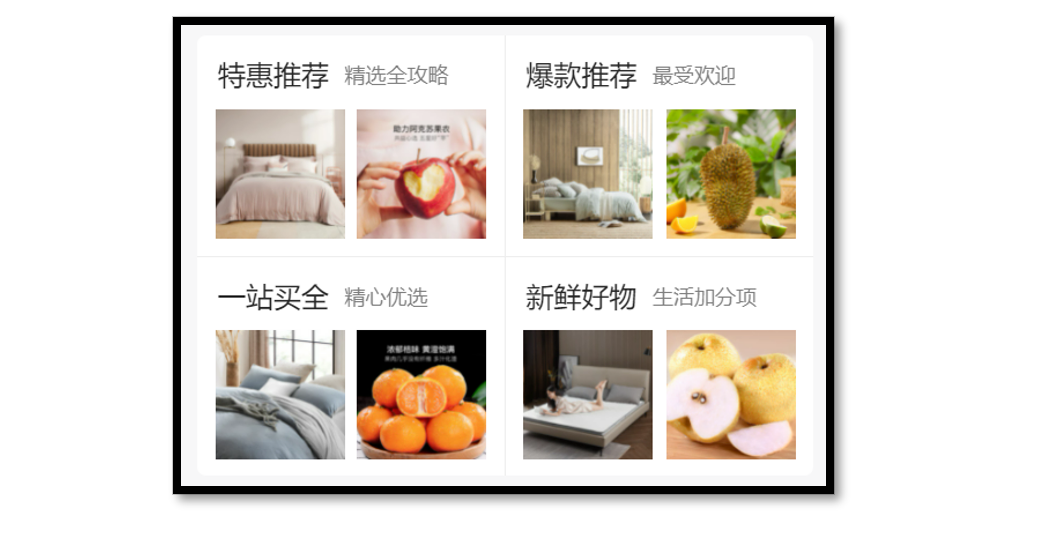


### 推荐面板静态结构

新建 `src/pages/index/components/HotPanel.vue`：


```vue
<script setup lang="ts">
//
</script>

<template>
  <!-- 推荐专区 -->
  <view class="panel hot">
    <view class="item" v-for="item in 4" :key="item">
      <view class="title">
        <text class="title-text">特惠推荐</text>
        <text class="title-desc">精选全攻略</text>
      </view>
      <navigator hover-class="none" url="/pages/hot/hot" class="cards">
        <image
          class="image"
          mode="aspectFit"
          src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/goods_small_1.jpg"
        ></image>
        <image
          class="image"
          mode="aspectFit"
          src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/goods_small_2.jpg"
        ></image>
      </navigator>
    </view>
  </view>
</template>

<style lang="scss">
/* 热门推荐 */
.hot {
  display: flex;
  flex-wrap: wrap;
  min-height: 508rpx;
  margin: 20rpx 20rpx 0;
  border-radius: 10rpx;
  background-color: #fff;

  .title {
    display: flex;
    align-items: center;
    padding: 24rpx 24rpx 0;
    font-size: 32rpx;
    color: #262626;
    position: relative;
    .title-desc {
      font-size: 24rpx;
      color: #7f7f7f;
      margin-left: 18rpx;
    }
  }

  .item {
    display: flex;
    flex-direction: column;
    width: 50%;
    height: 254rpx;
    border-right: 1rpx solid #eee;
    border-top: 1rpx solid #eee;
    .title {
      justify-content: start;
    }
    &:nth-child(2n) {
      border-right: 0 none;
    }
    &:nth-child(-n + 2) {
      border-top: 0 none;
    }
    .image {
      width: 150rpx;
      height: 150rpx;
    }
  }
  .cards {
    flex: 1;
    padding: 15rpx 20rpx;
    display: flex;
    justify-content: space-between;
    align-items: center;
  }
}
</style>
```

面板用 `width: 50%` 排成两列。`:nth-child(2n)` 去掉每行最后一项的右边框，`:nth-child(-n + 2)` 去掉第一行的上边框。后续动态版本保留这些样式。


### 获取推荐数据

| 项目 | 内容 |
| --- | --- |
| 方法和路径 | `GET /home/hot/mutli` |
| 必需 Header | `source-client: miniapp` |
| 主要响应字段 | `id`、`title`、`type`、`alt`、`pictures` |

01 的请求拦截器已经统一添加来源 Header，接口函数不必每次重复写。

在 `src/types/home.d.ts` 中追加原课的类型定义：


```typescript
/** 首页-热门推荐数据类型 */
export type HotItem = {
  /** 说明 */
  alt: string
  /** id */
  id: string
  /** 图片集合[ 图片路径 ] */
  pictures: string[]
  /** 跳转地址 */
  target: string
  /** 标题 */
  title: string
  /** 推荐类型 */
  type: string
}
```

> **原稿差异**：讲义响应表把 `type` 写为 `number`，类型定义写为 `string`，且类型里增加了 `target`。这里保留原课代码；使用时以实际接口文档和返回结构为准。泛型声明不会把响应值转换成另一个类型。

在 `src/services/home.ts` 中追加：


```typescript
// services/home.ts
/**
 * 首页-热门推荐-小程序
 */
export const getHomeHotAPI = () => {
  return http<HotItem[]>({
    method: 'GET',
    url: '/home/hot/mutli',
  })
}
```

记得把 `HotItem` 合并到文件顶部的类型导入。轮播、分类和热门推荐均由首页取得列表，再通过 props 分别交给组件显示。


### 渲染热门推荐

将 `HotPanel.vue` 的脚本与模板替换为：


```vue
<script setup lang="ts">
import type { HotItem } from '@/types/home'

// 定义 props 接收数据
defineProps<{
  list: HotItem[]
}>()
</script>

<template>
  <!-- 推荐专区 -->
  <view class="panel hot">
    <view class="item" v-for="item in list" :key="item.id">
      <view class="title">
        <text class="title-text">{{ item.title }}</text>
        <text class="title-desc">{{ item.alt }}</text>
      </view>
      <navigator hover-class="none" :url="`/pages/hot/hot?type=${item.type}`" class="cards">
        <image
          v-for="src in item.pictures"
          :key="src"
          class="image"
          mode="aspectFit"
          :src="src"
        ></image>
      </navigator>
    </view>
  </view>
</template>
```

组件遍历推荐分组，再遍历每组的 `pictures`。标题与说明来自 `title` 和 `alt`，点击卡片把 `type` 作为查询参数传给 `/pages/hot/hot`。

父页面用 `<HotPanel :list="hotList" />` 传入数据。推荐详情页属于后续模块，本篇先保留这个导航入口。


## 猜你喜欢（重点难点）

猜你喜欢会在多个页面展示，因此封装为公共组件 `src/components/XtxGuess.vue`。它自己请求商品并管理分页；父页面管理滚动容器，在触底时通知它加载下一页。

准备顺序：组件静态结构 → 全局组件与实例类型 → 分页接口 → 滚动容器 → 分页与组件通信。

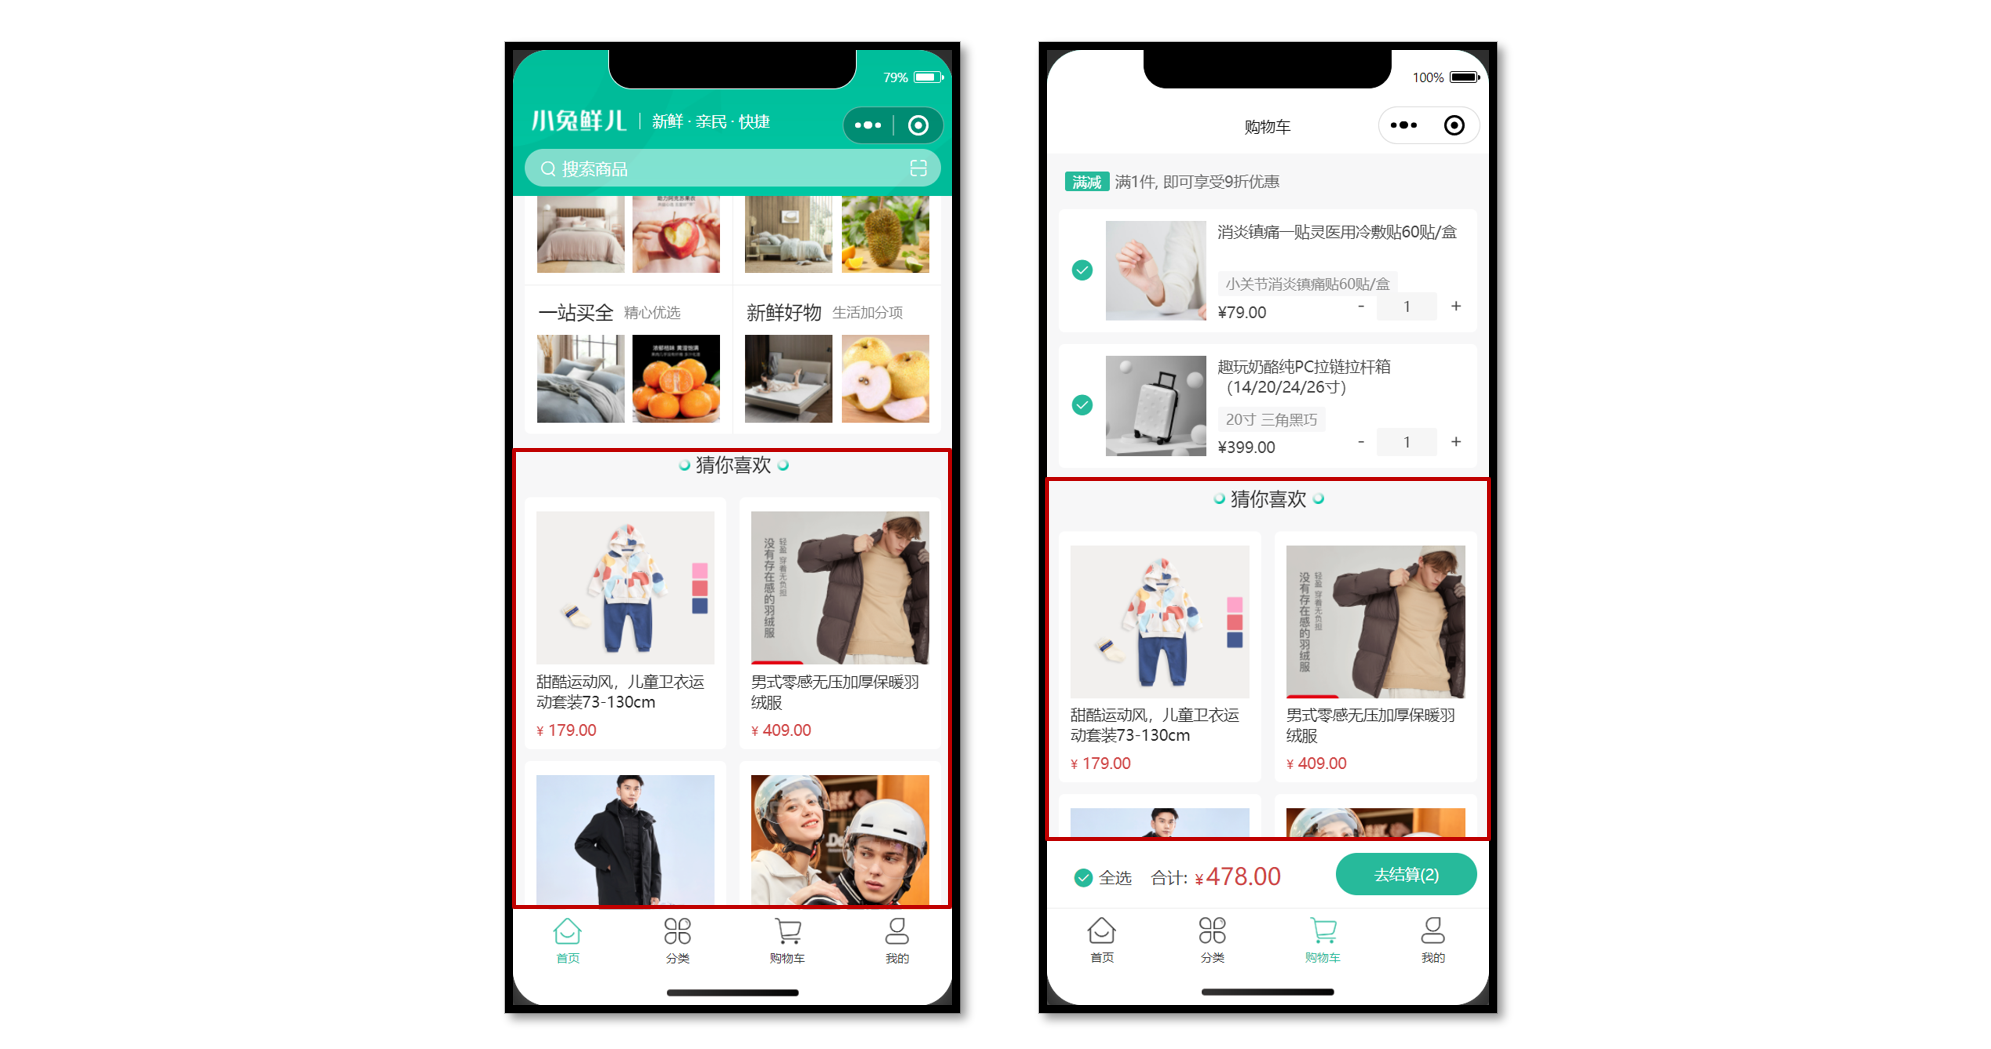


### 商品卡片静态结构

先创建 `src/components/XtxGuess.vue`：


```vue
<script setup lang="ts">
//
</script>

<template>
  <!-- 猜你喜欢 -->
  <view class="caption">
    <text class="text">猜你喜欢</text>
  </view>
  <view class="guess">
    <navigator
      class="guess-item"
      v-for="item in 10"
      :key="item"
      :url="`/pages/goods/goods?id=4007498`"
    >
      <image
        class="image"
        mode="aspectFill"
        src="https://pcapi-xiaotuxian-front-devtest.itheima.net/miniapp/uploads/goods_big_1.jpg"
      ></image>
      <view class="name"> 德国THORE男表 超薄手表男士休闲简约夜光石英防水直径40毫米 </view>
      <view class="price">
        <text class="small">¥</text>
        <text>899.00</text>
      </view>
    </navigator>
  </view>
  <view class="loading-text"> 正在加载... </view>
</template>

<style lang="scss">
:host {
  display: block;
}
/* 分类标题 */
.caption {
  display: flex;
  justify-content: center;
  line-height: 1;
  padding: 36rpx 0 40rpx;
  font-size: 32rpx;
  color: #262626;
  .text {
    display: flex;
    justify-content: center;
    align-items: center;
    padding: 0 28rpx 0 30rpx;

    &::before,
    &::after {
      content: '';
      width: 20rpx;
      height: 20rpx;
      background-image: url(@/static/images/bubble.png);
      background-size: contain;
      margin: 0 10rpx;
    }
  }
}

/* 猜你喜欢 */
.guess {
  display: flex;
  flex-wrap: wrap;
  justify-content: space-between;
  padding: 0 20rpx;
  .guess-item {
    width: 345rpx;
    padding: 24rpx 20rpx 20rpx;
    margin-bottom: 20rpx;
    border-radius: 10rpx;
    overflow: hidden;
    background-color: #fff;
  }
  .image {
    width: 304rpx;
    height: 304rpx;
  }
  .name {
    height: 75rpx;
    margin: 10rpx 0;
    font-size: 26rpx;
    color: #262626;
    overflow: hidden;
    text-overflow: ellipsis;
    display: -webkit-box;
    -webkit-line-clamp: 2;
    -webkit-box-orient: vertical;
  }
  .price {
    line-height: 1;
    padding-top: 4rpx;
    color: #cf4444;
    font-size: 26rpx;
  }
  .small {
    font-size: 80%;
  }
}
// 加载提示文字
.loading-text {
  text-align: center;
  font-size: 28rpx;
  color: #666;
  padding: 20rpx 0;
}
</style>
```

卡片以两列展示图片、名称和价格。名称通过 `-webkit-line-clamp: 2` 限制两行，底部预留加载文字。动态版本继续使用这里的 SCSS。

静态商品的固定 ID 和数据只用于观察布局，下一步换为接口返回的商品。


### 全局组件与实例类型

更新 `src/types/components.d.ts`，在原有轮播声明上增加 `XtxGuess`：


```typescript
// types/components.d.ts
import XtxSwiper from '@/components/XtxSwiper.vue'
import XtxGuess from '@/components/XtxGuess.vue'

declare module 'vue' {
  export interface GlobalComponents {
    XtxSwiper: typeof XtxSwiper
    XtxGuess: typeof XtxGuess
  }
}

// 组件实例类型
export type XtxGuessInstance = InstanceType<typeof XtxGuess>
```

`GlobalComponents` 让模板识别全局组件；`InstanceType<typeof XtxGuess>` 取得组件实例类型，让父页面的组件引用能提示公开方法。

该组件名已经匹配 `^Xtx(.*)` 的 easycom 规则，不需要再追加同类规则。


### 分页接口与类型

猜你喜欢接口：

| 项目 | 内容 |
| --- | --- |
| 方法与路径 | `GET /home/goods/guessLike` |
| `page` | 可选，默认 `1` |
| `pageSize` | 可选，默认 `10` |

新建 `src/types/global.d.ts`，放入通用分页结果和参数类型：


```typescript
/** 通用分页结果类型 */
export type PageResult<T> = {
  /** 列表数据 */
  items: T[]
  /** 总条数 */
  counts: number
  /** 当前页数 */
  page: number
  /** 总页数 */
  pages: number
  /** 每页条数 */
  pageSize: number
}
```

```typescript
/** 通用分页参数类型 */
export type PageParams = {
  /** 页码：默认值为 1 */
  page?: number
  /** 页大小：默认值为 10 */
  pageSize?: number
}
```

`PageResult<T>` 用泛型复用“分页外层结构”，`items` 才是本页的数据列表。`pages` 是总页数，`counts` 是总记录数。

在 `src/types/home.d.ts` 中追加商品类型：


```typescript
/** 猜你喜欢-商品类型 */
export type GuessItem = {
  /** 商品描述 */
  desc: string
  /** 商品折扣 */
  discount: number
  /** id */
  id: string
  /** 商品名称 */
  name: string
  /** 商品已下单数量 */
  orderNum: number
  /** 商品图片 */
  picture: string
  /** 商品价格 */
  price: number
}
```

在 `src/services/home.ts` 中追加猜你喜欢接口：


```typescript
// src/services/home.ts
/**
 * 猜你喜欢-小程序
 */
export const getHomeGoodsGuessLikeAPI = (data?: PageParams) => {
  return http<PageResult<GuessItem>>({
    method: 'GET',
    url: '/home/goods/guessLike',
    data,
  })
}
```

补齐文件顶部的类型导入后，首页服务文件的 import 汇总为：


```typescript
import { http } from '@/utils/http'
import type { BannerItem, CategoryItem, GuessItem, HotItem } from '@/types/home'
import type { PageParams, PageResult } from '@/types/global'
```

这些 import 合并到同一文件顶部；前面四个接口函数保留在同一个 `home.ts` 中。


### 为触底事件准备滚动容器

原课首页的核心片段是：


```vue
<!-- pages/index/index.vue -->
<script setup lang="ts">
import type { XtxGuessInstance } from '@/types/components'
import { ref } from 'vue'
// 获取猜你喜欢组件实例
const guessRef = ref<XtxGuessInstance>()

// 滚动触底事件
const onScrolltolower = () => {
  guessRef.value?.getMore()
}
</script>

<template>
  <!-- 滚动容器 -->
  <scroll-view scroll-y @scrolltolower="onScrolltolower">
    <!-- 猜你喜欢 -->
    <XtxGuess ref="guessRef" />
  </scroll-view>
</template>
```

父页面通过 `ref="guessRef"` 获得子组件实例。触底事件 `scrolltolower` 发生后，调用子组件公开的 `getMore()`。

`scroll-view` 必须有确定的可用高度，才能产生内部滚动。原稿列出了“设置 page 和 scroll-view 样式”，但没有展开；下面补齐本步骤所需的布局片段：


```vue
<template>
  <CustomNavbar />
  <scroll-view class="scroll-view" scroll-y @scrolltolower="onScrolltolower">
    <!-- 轮播、分类、热门推荐也放在这里 -->
    <XtxGuess ref="guessRef" />
  </scroll-view>
</template>

<style lang="scss">
page {
  height: 100%;
  display: flex;
  flex-direction: column;
  background-color: #f7f7f7;
}
.scroll-view {
  flex: 1;
  height: 0;
  min-height: 0;
}
</style>
```

导航栏放在滚动容器外，内容滚动时保持在顶部；`flex: 1` 让内容占满剩余高度，`height: 0` 配合 flex 约束滚动容器。

这是内部 `scroll-view` 的触底事件，后面的下拉刷新也使用这个容器，不混用页面级滚动事件。


### 子组件内获取数据与分页

`src/components/XtxGuess.vue` 的动态版本：


```vue
<!-- src/components/XtxGuess.vue -->
<script setup lang="ts">
import { getHomeGoodsGuessLikeAPI } from '@/services/home'
import type { PageParams } from '@/types/global'
import type { GuessItem } from '@/types/home'
import { onMounted, ref } from 'vue'

// 分页参数
const pageParams: Required<PageParams> = {
  page: 1,
  pageSize: 10,
}
// 猜你喜欢的列表
const guessList = ref<GuessItem[]>([])
// 已结束标记
const finish = ref(false)
// 获取猜你喜欢数据
const getHomeGoodsGuessLikeData = async () => {
  // 退出分页判断
  if (finish.value === true) {
    return uni.showToast({ icon: 'none', title: '没有更多数据~' })
  }
  const res = await getHomeGoodsGuessLikeAPI(pageParams)
  // 数组追加
  guessList.value.push(...res.result.items)
  // 分页条件
  if (pageParams.page < res.result.pages) {
    // 页码累加
    pageParams.page++
  } else {
    finish.value = true
  }
}
// 重置数据
const resetData = () => {
  pageParams.page = 1
  guessList.value = []
  finish.value = false
}
// 组件挂载完毕
onMounted(() => {
  getHomeGoodsGuessLikeData()
})
// 暴露方法
defineExpose({
  resetData,
  getMore: getHomeGoodsGuessLikeData,
})
</script>

<template>
  <!-- 猜你喜欢 -->
  <view class="caption">
    <text class="text">猜你喜欢</text>
  </view>
  <view class="guess">
    <navigator
      class="guess-item"
      v-for="item in guessList"
      :key="item.id"
      :url="`/pages/goods/goods`"
    >
      <image class="image" mode="aspectFill" :src="item.picture"></image>
      <view class="name"> {{ item.name }} </view>
      <view class="price">
        <text class="small">¥</text>
        <text>{{ item.price }}</text>
      </view>
    </navigator>
  </view>
  <view class="loading-text">
    {{ finish ? '没有更多数据~' : '正在加载...' }}
  </view>
</template>
```

保留静态结构中的样式。`Required<PageParams>` 把原本可选的 `page`、`pageSize` 转为组件内部必需字段，方便直接累加页码。

一次请求完成后的处理顺序：

1. 如果 `finish` 为 `true`，提示没有更多数据并退出。
2. 请求当前页。
3. 用 `push(...res.result.items)` **追加**商品，保留之前的列表。
4. 当前页小于总页数时，页码加一；否则标记 `finish = true`。

`onMounted` 负责组件首次加载。`resetData` 恢复第 1 页、清空列表、取消结束标记，它本身**没有发起请求**。

> 原课模板的商品导航还没有把 `item.id` 传给详情页；本篇保留这个阶段的写法，商品详情的完整路由参数在后续模块处理。

跟做时观察第 1 页后继续触底，确认旧数据保留、页码递增，最后一页出现“没有更多数据~”。原课示例没有并发请求锁，快速连续触底可能重复请求同一页。


### 父子组件如何配合

| 场景 | 数据或方法的流向 |
| --- | --- |
| 轮播、分类、热门推荐 | 父页面请求数据 → 用 props 传给子组件 |
| 猜你喜欢首次显示 | 子组件在 `onMounted` 请求自己的数据 |
| 父容器滚动触底 | 父页面通过组件引用调用子组件 `getMore` |
| 下拉刷新 | 父页面调用子组件 `resetData`，再调用 `getMore` |

`<script setup>` 中的方法不会自动成为组件实例的公开方法，必须通过 `defineExpose` 暴露。这里把内部的 `getHomeGoodsGuessLikeData` 用公开名 `getMore` 暴露出去。

原稿步骤写“子调父”，实际代码是**父组件调用子组件方法**。`guessRef.value?.getMore()` 的可选链用于组件尚未挂载、实例暂时不存在的情况。


## 下拉刷新

下拉刷新就是重新请求数据并更新页面。原课基于 `scroll-view` 实现：

| 配置或事件 | 作用 |
| --- | --- |
| `refresher-enabled` | 开启下拉刷新交互 |
| `@refresherrefresh` | 用户触发下拉时执行刷新函数 |
| `:refresher-triggered` | 用响应式状态控制刷新动画 |

### 重置猜你喜欢的状态

原课在 `XtxGuess.vue` 中再次展示重置方法：


```typescript
// src/components/XtxGuess.vue
// 重置数据
const resetData = () => {
  pageParams.page = 1
  guessList.value = []
  finish.value = false
}
// 暴露方法
defineExpose({
  resetData,
})
```

这段是已有组件的局部片段，合并时保留此前的 `getMore`，不要用仅包含 `resetData` 的 `defineExpose` 覆盖全部公开方法。最终保持：


```typescript
defineExpose({
  resetData,
  getMore: getHomeGoodsGuessLikeData,
})
```


### 触发刷新并关闭动画

讲义中的首页片段：


```vue
<!-- src/pages/index/index.vue -->
<script setup lang="ts">
// 下拉刷新状态
const isTriggered = ref(false)
// 自定义下拉刷新被触发
const onRefresherrefresh = async () => {
  // 开启动画
  isTriggered.value = true
  // 重置猜你喜欢组件数据
  guessRef.value?.resetData() // 加载数据
  await Promise.all([getHomeBannerData(), getHomeCategoryData(), getHomeHotData()]) // 关闭动画
  isTriggered.value = false
}
</script>

<!-- 滚动容器 -->
<scroll-view
  refresher-enabled
  @refresherrefresh="onRefresherrefresh"
  :refresher-triggered="isTriggered"
  class="scroll-view"
  scroll-y
>
  …省略
</scroll-view>
```

`getHomeBannerData`、`getHomeCategoryData`、`getHomeHotData` 分别是首页请求并保存对应列表的函数，下文把它们补齐。

> **原稿逻辑补充**：`resetData()` 只清空猜你喜欢，没有重新加载；上面的 `Promise.all` 也没有包含猜你喜欢请求。只照抄这一片段，刷新后商品列表会一直为空，直到再次触底。

把刷新函数调整为：


```typescript
const isTriggered = ref(false)

const onRefresherrefresh = async () => {
  isTriggered.value = true
  guessRef.value?.resetData()
  try {
    await Promise.all([
      getHomeBannerData(),
      getHomeCategoryData(),
      getHomeHotData(),
      guessRef.value?.getMore(),
    ])
  } finally {
    isTriggered.value = false
  }
}
```

先把猜你喜欢恢复为第 1 页，再重新加载四个区域。`finally` 确保请求失败时也结束刷新动画；错误提示继续由 01 的请求封装提供。`Promise.all` 汇总请求，任意请求失败会使它拒绝，其他已经发出的请求仍会继续。

跟做时先加载两页商品，再下拉刷新，确认列表回到第 1 页而不是重复累加，且请求失败时动画也会结束。


## 骨架屏

骨架屏用灰色区块勾勒尚未加载完成的页面，让用户知道内容正在准备。接口数据回来后，再用真实内容替换它。它改善等待体验，不会减少接口本身的耗时。

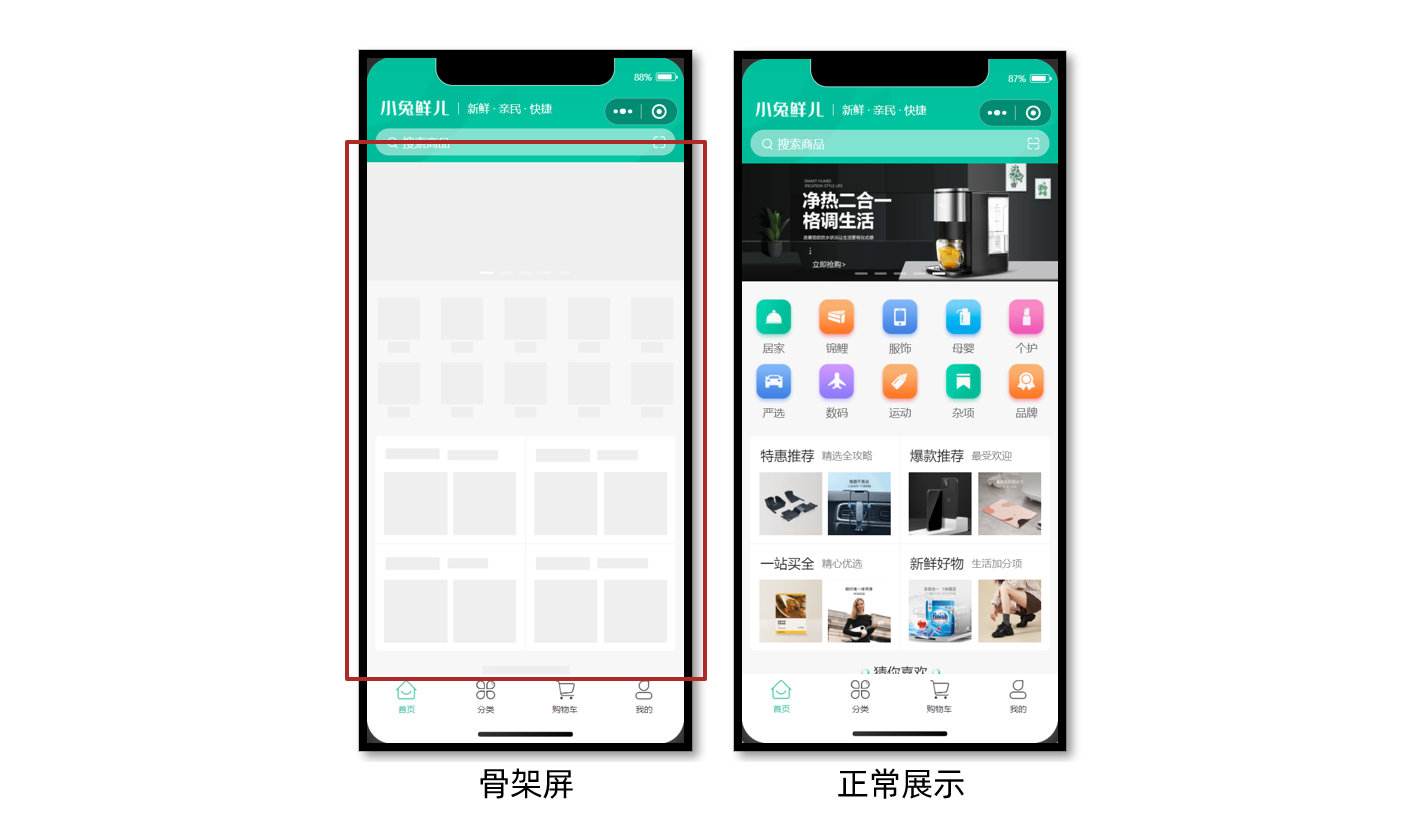


### 在开发者工具中生成并封装

原课操作过程：

1. 先运行已经能正常展示数据的首页。
2. 在微信开发者工具模拟器的“页面信息”菜单选择“生成骨架屏”。
3. 找到生成的骨架结构与样式文件。
4. 整理为首页业务组件 `PageSkeleton.vue`，供页面按加载状态切换。

> **原稿文件名修正**：正文写成 `xxx.skeleton.vue`，但下方操作截图显示生成的是 `index.skeleton.wxml` 和 `index.skeleton.wxss`。生成的是小程序结构与样式，需要再封装为 Vue 组件。

将生成的 WXML 结构放进 `PageSkeleton.vue` 的 `<template>`，把 WXSS 内容整理到 `<style>`；包含数据绑定或平台专用写法时，按 Vue/uni-app 语法调整。生成代码位于编译输出目录，整理后的业务组件应保存到 `src/pages/index/components`，避免下次编译覆盖。

原资料没有提供这两个生成文件的完整文本，骨架内容需要根据自己的首页通过工具生成；下面保留真实的操作截图与加载切换方法。

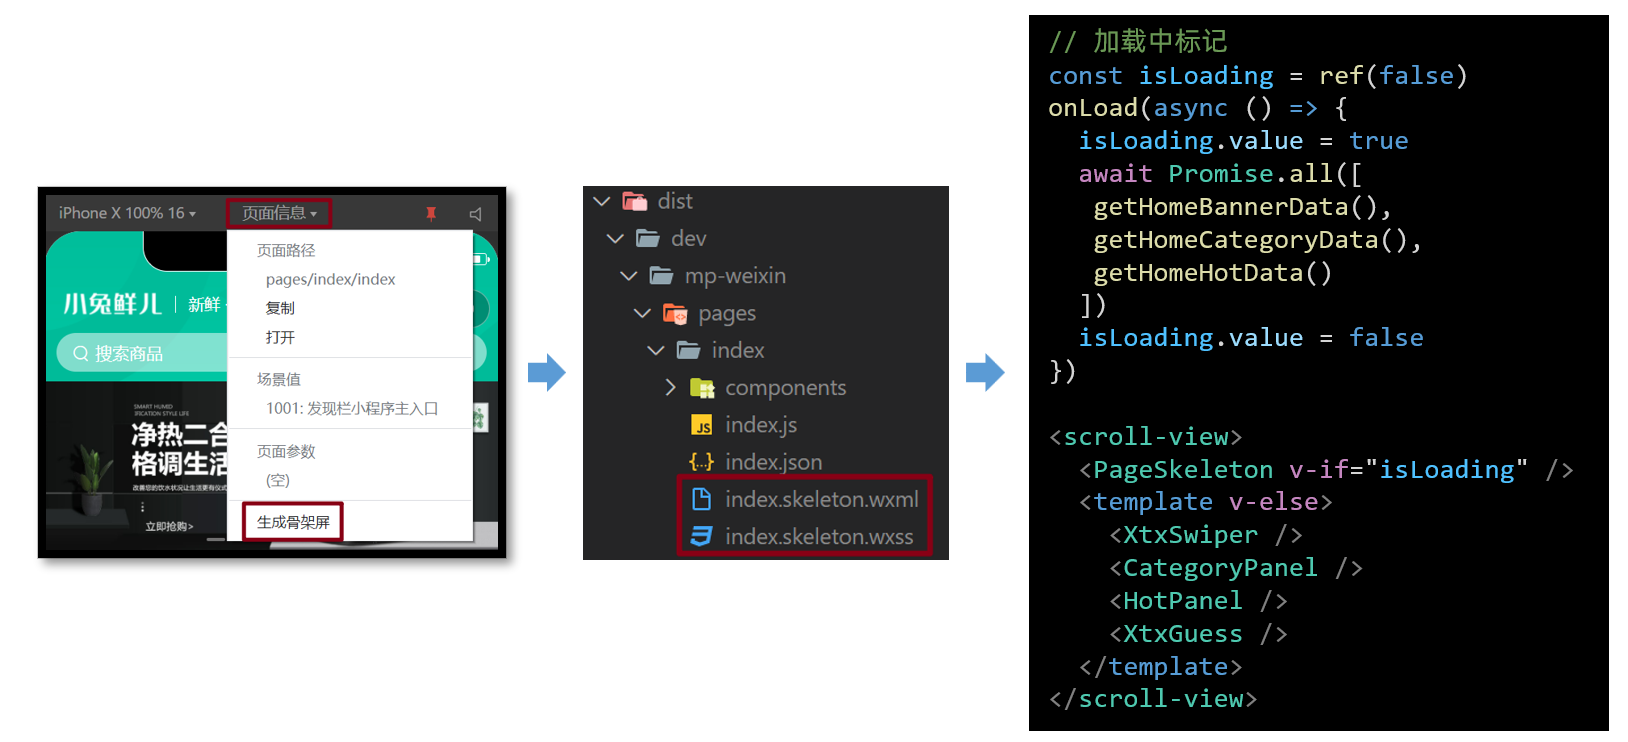


### 按首次加载状态切换

截图中使用 `isLoading` 作为页面首次加载标记：请求首页三组数据时显示 `PageSkeleton`，请求完成后切换真实组件。

`<template v-else>` 可以同时包住轮播、分类、热门推荐和猜你喜欢；`v-else` 要紧跟 `v-if`。猜你喜欢在真实内容出现、组件挂载后加载自己的第 1 页数据，因此没有重复加入页面首次加载的三个请求。

下拉刷新使用的是 `isTriggered`，并不需要再次切换整页骨架；这样能保留已经挂载的猜你喜欢实例，供刷新函数重置并重新请求。


### 首页片段怎样合并

下面是**根据本篇各步骤整理的首页组合示例**，用于补齐原稿没有展开的数据保存、组件使用和滚动布局。它不是包内提供的完整源码。

使用前先完成各组件、接口和类型声明，并按上面的工具步骤生成和封装 `PageSkeleton.vue`。`CustomNavbar`、`CategoryPanel`、`HotPanel`、`PageSkeleton` 是首页业务组件，需要显式导入；`XtxSwiper`、`XtxGuess` 由 easycom 自动导入。

将前面介绍的首页逻辑合并到 `src/pages/index/index.vue`：


```vue
<script setup lang="ts">
import CustomNavbar from './components/CustomNavbar.vue'
import CategoryPanel from './components/CategoryPanel.vue'
import HotPanel from './components/HotPanel.vue'
import PageSkeleton from './components/PageSkeleton.vue'
import { getHomeBannerAPI, getHomeCategoryAPI, getHomeHotAPI } from '@/services/home'
import type { BannerItem, CategoryItem, HotItem } from '@/types/home'
import type { XtxGuessInstance } from '@/types/components'
import { onLoad } from '@dcloudio/uni-app'
import { ref } from 'vue'

const bannerList = ref<BannerItem[]>([])
const categoryList = ref<CategoryItem[]>([])
const hotList = ref<HotItem[]>([])
const guessRef = ref<XtxGuessInstance>()

const getHomeBannerData = async () => {
  const res = await getHomeBannerAPI()
  bannerList.value = res.result
}
const getHomeCategoryData = async () => {
  const res = await getHomeCategoryAPI()
  categoryList.value = res.result
}
const getHomeHotData = async () => {
  const res = await getHomeHotAPI()
  hotList.value = res.result
}

const onScrolltolower = () => {
  guessRef.value?.getMore()
}

const isTriggered = ref(false)
const onRefresherrefresh = async () => {
  isTriggered.value = true
  guessRef.value?.resetData()
  try {
    await Promise.all([
      getHomeBannerData(),
      getHomeCategoryData(),
      getHomeHotData(),
      guessRef.value?.getMore(),
    ])
  } finally {
    isTriggered.value = false
  }
}

const isLoading = ref(true)
onLoad(async () => {
  try {
    await Promise.all([
      getHomeBannerData(),
      getHomeCategoryData(),
      getHomeHotData(),
    ])
  } finally {
    isLoading.value = false
  }
})
</script>

<template>
  <CustomNavbar />
  <scroll-view
    class="scroll-view"
    scroll-y
    @scrolltolower="onScrolltolower"
    refresher-enabled
    @refresherrefresh="onRefresherrefresh"
    :refresher-triggered="isTriggered"
  >
    <PageSkeleton v-if="isLoading" />
    <template v-else>
      <XtxSwiper :list="bannerList" />
      <CategoryPanel :list="categoryList" />
      <HotPanel :list="hotList" />
      <XtxGuess ref="guessRef" />
    </template>
  </scroll-view>
</template>

<style lang="scss">
page {
  height: 100%;
  display: flex;
  flex-direction: column;
  background-color: #f7f7f7;
}
.scroll-view {
  flex: 1;
  height: 0;
  min-height: 0;
}
</style>
```

页面数据更新使用 `res.result`；首次加载与下拉刷新分别使用 `isLoading` 和 `isTriggered`。猜你喜欢组件内部的首次加载、分页参数、结束标记和 `defineExpose` 保留在 `XtxGuess.vue`。


## 本篇完成检查

按首页开发顺序检查：

- [ ] 默认导航已隐藏，自定义导航在不同机型上没有遮住重要内容。
- [ ] `Xtx` 自动导入规则和全局组件类型均已配置。
- [ ] 轮播、分类、热门推荐的接口数据已通过 props 传入对应组件。
- [ ] 轮播滑动时指示点跟随变化。
- [ ] `scroll-view` 能内部滚动，触底事件能调用猜你喜欢 `getMore`。
- [ ] 分页使用追加方式，最后一页停止继续请求。
- [ ] 下拉刷新把猜你喜欢恢复为第 1 页并重新加载，失败时也结束动画。
- [ ] 首次请求时显示骨架屏，完成后切换真实首页。
- [ ] 静态组件中的 SCSS 在动态改造后仍保留。

本篇完成首页展示与加载流程。分类、广告和商品的部分导航仍是原课阶段性占位，按后续模块继续完善。
